In [1]:
import statsmodels.api as sm
from sklearn import datasets 
import numpy as np
import matplotlib.pyplot as plt
from sklearn import linear_model
import pandas as pd
import seaborn as sns
from statsmodels.stats.outliers_influence import variance_inflation_factor
import sklearn
from sklearn.model_selection import train_test_split
import statsmodels.stats.api as sms
from sklearn import metrics
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn import tree
from sklearn.preprocessing import StandardScaler
import math
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import nltk
from nltk import NLTKWordTokenizer
from nltk.tokenize import sent_tokenize
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.probability import FreqDist
from nltk.stem.snowball import SnowballStemmer
from nltk.stem.wordnet import WordNetLemmatizer
import re
import vaderSentiment
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
import textblob
from textblob import TextBlob
import wordcloud
from wordcloud import WordCloud 
from collections import Counter
import string
from bs4 import BeautifulSoup

identify the 15 most common words used in online product reviews. 

In [2]:
reviews = pd.read_csv("C:\\Users\\andre\\Desktop\\Python_DA\\turtle_reviews.csv")

In [3]:
rsdrop = reviews.iloc[51]
rsdrop

gender                                                                 Male
age                                                                      35
remuneration (k£)                                                     34.44
spending_score (1-100)                                                   60
loyalty_points                                                         1395
education                                                      postgraduate
language                                                                 EN
platform                                                                Web
product                                                                3865
review                    <div id="video-block-R3BD06E4PUN30" class="a-s...
summary                   I Like Every Image Contained In This Stained G...
Name: 51, dtype: object

In [4]:
reviews = reviews.drop(51, axis=0)

In [5]:
rs = pd.DataFrame(reviews['review'])

In [6]:
rs.isna().sum()

review    0
dtype: int64

In [7]:
rs.shape

(1999, 1)

In [8]:
rs.head()

,review
0,"When it comes to a DM's screen, the space on t..."
1,An Open Letter to GaleForce9*:\n\nYour unpaint...
2,"Nice art, nice printing. Why two panels are f..."
3,Amazing buy! Bought it as a gift for our new d...
4,As my review of GF9's previous screens these w...


In [9]:
#Transform data to lowercase. 
rs['review'] = rs['review'].apply(lambda x: " ".join(x.lower() for x in x.split()))
rs.head()

,review
0,"when it comes to a dm's screen, the space on t..."
1,an open letter to galeforce9*: your unpainted ...
2,"nice art, nice printing. why two panels are fi..."
3,amazing buy! bought it as a gift for our new d...
4,as my review of gf9's previous screens these w...


In [10]:
rs.shape

(1999, 1)

In [11]:
#Remove punctuation.
remove = [".", "?", "!", ",", ":", ";", "'s", "9", "*", "n't"]

def remove_punctuation(string):
    result = ""
    for char in string:
        if char not in remove:
            result += char
    return result

rs['review'] = rs['review'].apply(remove_punctuation)

In [12]:
#Process HTML links.
def clean_html(html):
    soup = BeautifulSoup(html, "html.parser")
    for data in soup(['style', 'script', 'code', 'a']):
        data.decompose()
    return ' '.join(soup.stripped_strings)

rs['review'] = rs['review'].apply(lambda x: clean_html(x))

C:\Users\andre\AppData\Local\Temp\ipykernel_11908\1842229064.py:3: MarkupResemblesLocatorWarning: The input looks more like a filename than markup. You may want to open this file and pass the filehandle into Beautiful Soup.
  soup = BeautifulSoup(html, "html.parser")


In [13]:
rs.head()

,review
0,when it comes to a dm's screen the space on th...
1,an open letter to galeforce your unpainted min...
2,nice art nice printing why two panels are fill...
3,amazing buy bought it as a gift for our new dm...
4,as my review of gf's previous screens these we...


In [14]:
#Create a list of the reviews. 
rs_list = rs['review'].values.tolist()
print("Reviews List:", rs_list)

Reviews List: ["when it comes to a dm's screen the space on the screen itself is at an absolute premium the fact that 50% of this space is wasted on art (and not terribly informative or needed art as well) makes it completely useless the only reason that i gave it 2 stars and not 1 was that technically speaking it can at least still stand up to block your notes and dice rolls other than that it drops the ball completely", 'an open letter to galeforce your unpainted miniatures are very not bad your spell cards are great your board games are "meh" your dm screens however are freaking terrible i\'m still waiting for a single screen that isn\'t polluted with pointless artwork where useful reference-able tables should be once again you\'ve created a single use screen that is only useful when running the "storm king\'s thunder" adventure even despite the fact that it\'s geared to that adventure path it\'s usefulness negligible at best i massive swath of the inner panel is wasted on artwork a

In [15]:
#Convert this list to just string elements.
text = ' '.join(rs_list)
print(text)

when it comes to a dm's screen the space on the screen itself is at an absolute premium the fact that 50% of this space is wasted on art (and not terribly informative or needed art as well) makes it completely useless the only reason that i gave it 2 stars and not 1 was that technically speaking it can at least still stand up to block your notes and dice rolls other than that it drops the ball completely an open letter to galeforce your unpainted miniatures are very not bad your spell cards are great your board games are "meh" your dm screens however are freaking terrible i'm still waiting for a single screen that isn't polluted with pointless artwork where useful reference-able tables should be once again you've created a single use screen that is only useful when running the "storm king's thunder" adventure even despite the fact that it's geared to that adventure path it's usefulness negligible at best i massive swath of the inner panel is wasted on artwork and a bloated overland map

In [16]:
#Split the string into individual words.
tokenised_word = word_tokenize(text)
print(tokenised_word)

['when', 'it', 'comes', 'to', 'a', 'dm', "'s", 'screen', 'the', 'space', 'on', 'the', 'screen', 'itself', 'is', 'at', 'an', 'absolute', 'premium', 'the', 'fact', 'that', '50', '%', 'of', 'this', 'space', 'is', 'wasted', 'on', 'art', '(', 'and', 'not', 'terribly', 'informative', 'or', 'needed', 'art', 'as', 'well', ')', 'makes', 'it', 'completely', 'useless', 'the', 'only', 'reason', 'that', 'i', 'gave', 'it', '2', 'stars', 'and', 'not', '1', 'was', 'that', 'technically', 'speaking', 'it', 'can', 'at', 'least', 'still', 'stand', 'up', 'to', 'block', 'your', 'notes', 'and', 'dice', 'rolls', 'other', 'than', 'that', 'it', 'drops', 'the', 'ball', 'completely', 'an', 'open', 'letter', 'to', 'galeforce', 'your', 'unpainted', 'miniatures', 'are', 'very', 'not', 'bad', 'your', 'spell', 'cards', 'are', 'great', 'your', 'board', 'games', 'are', '``', 'meh', "''", 'your', 'dm', 'screens', 'however', 'are', 'freaking', 'terrible', 'i', "'m", 'still', 'waiting', 'for', 'a', 'single', 'screen', 'tha

In [17]:
rs.to_csv("C:\\Users\\andre\\Desktop\\Python_DA\\rs.csv")

In [18]:
freq_dist_of_words = FreqDist(tokenised_word)
freq_dist_of_words.most_common(5)

[('the', 5447), ('and', 3234), ('to', 3162), ('a', 3158), ('it', 2488)]

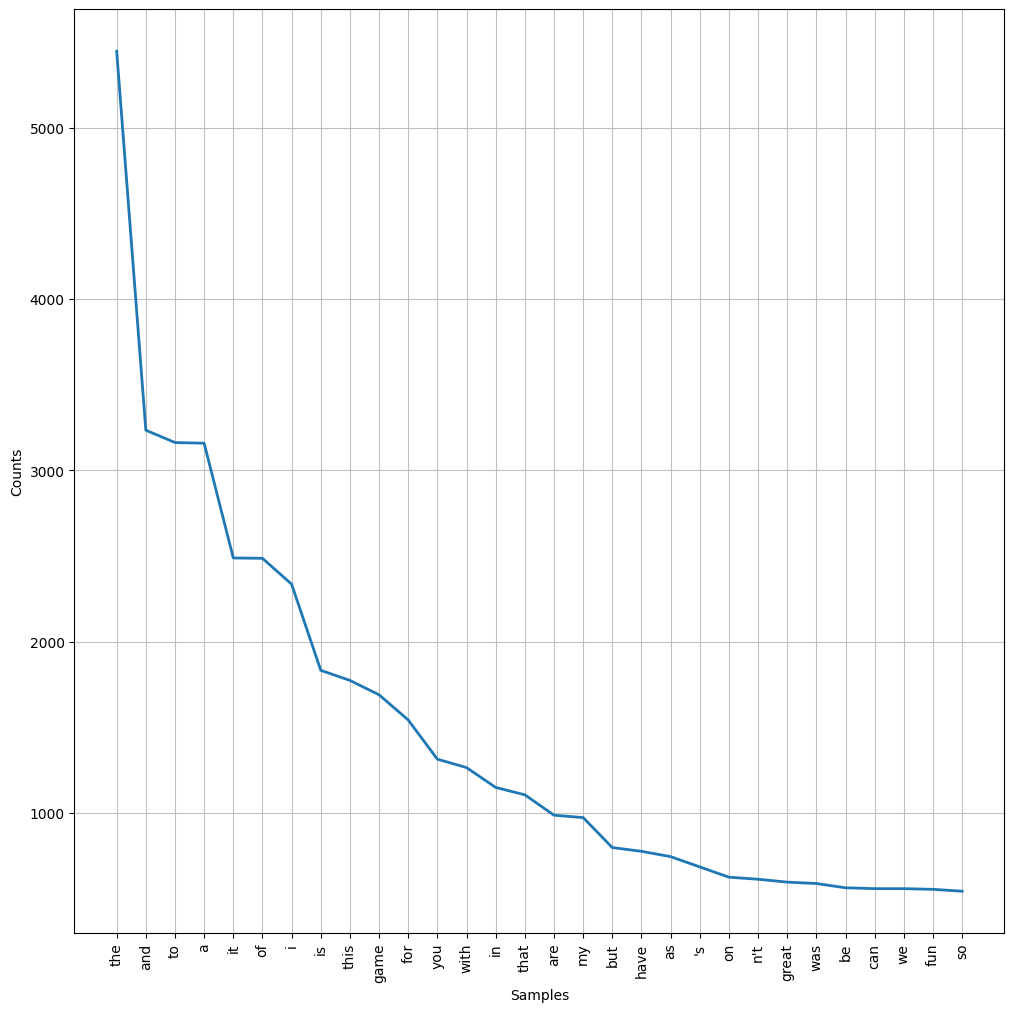

In [19]:
fig, ax = plt.subplots(dpi=100)
fig.set_size_inches(12, 12)

freq_dist_of_words.plot(30, cumulative=False)

plt.show()

I normalise the data. 

In [20]:
stop_words = set(stopwords.words('english'))
print(stop_words)

{'ma', 'needn', 'these', 'm', 'mightn', 'nor', "you're", 'isn', 'shouldn', 'd', 'most', 'here', 'you', 'too', 'by', 'than', 'y', "she's", 'for', "that'll", 'any', 'more', 'ours', 'wouldn', 'until', 'into', 'hadn', 'yours', 'has', "you'd", 'few', 'which', 'o', "aren't", 'when', 'same', 'can', 'ain', 'down', 'aren', 'is', 'his', 'shan', 'each', 'very', 'out', 'himself', "weren't", 'yourself', 'we', 'on', "you'll", 'me', 'your', 'if', 'her', 'does', 'all', 'mustn', 'what', 'herself', 'where', 'be', 'him', "couldn't", "it's", 'up', 'were', 'll', 'i', "didn't", "mightn't", 'during', 'wasn', 'such', 'doing', 'it', 'am', 'once', 'other', 'again', "shan't", 't', 'not', 'off', 'just', 'of', "hadn't", 'will', 'between', 'before', 'while', 'its', 'that', 'should', 'itself', 'doesn', 'and', "isn't", 'only', 'yourselves', 's', 'myself', 'being', 'did', 'their', "wouldn't", 'who', 'do', 'having', 'from', 'further', 'now', "don't", 'some', 'above', "shouldn't", 'below', 'to', 'whom', "doesn't", 'she'

In [21]:
filtered_text = []

In [22]:
tokenised_word = nltk.word_tokenize(text)

In [23]:
for each_word in tokenised_word:
    if each_word not in stop_words:  
        filtered_text.append(each_word)

In [24]:
print("Tokenised list without stopwords: {}".format(filtered_text))

Tokenised list without stopwords: ['comes', 'dm', "'s", 'screen', 'space', 'screen', 'absolute', 'premium', 'fact', '50', '%', 'space', 'wasted', 'art', '(', 'terribly', 'informative', 'needed', 'art', 'well', ')', 'makes', 'completely', 'useless', 'reason', 'gave', '2', 'stars', '1', 'technically', 'speaking', 'least', 'still', 'stand', 'block', 'notes', 'dice', 'rolls', 'drops', 'ball', 'completely', 'open', 'letter', 'galeforce', 'unpainted', 'miniatures', 'bad', 'spell', 'cards', 'great', 'board', 'games', '``', 'meh', "''", 'dm', 'screens', 'however', 'freaking', 'terrible', "'m", 'still', 'waiting', 'single', 'screen', "n't", 'polluted', 'pointless', 'artwork', 'useful', 'reference-able', 'tables', "'ve", 'created', 'single', 'use', 'screen', 'useful', 'running', '``', 'storm', 'king', "'s", 'thunder', "''", 'adventure', 'even', 'despite', 'fact', "'s", 'geared', 'adventure', 'path', "'s", 'usefulness', 'negligible', 'best', 'massive', 'swath', 'inner', 'panel', 'wasted', 'artwor

In [25]:
filtered_text = [word for word in filtered_text if word.isalnum()]

In [26]:
#Lemmatize the words in the list. 
lemmatizer = WordNetLemmatizer()

lemmatized_words = [lemmatizer.lemmatize(word) for word in filtered_text]

print(filtered_text)

['comes', 'dm', 'screen', 'space', 'screen', 'absolute', 'premium', 'fact', '50', 'space', 'wasted', 'art', 'terribly', 'informative', 'needed', 'art', 'well', 'makes', 'completely', 'useless', 'reason', 'gave', '2', 'stars', '1', 'technically', 'speaking', 'least', 'still', 'stand', 'block', 'notes', 'dice', 'rolls', 'drops', 'ball', 'completely', 'open', 'letter', 'galeforce', 'unpainted', 'miniatures', 'bad', 'spell', 'cards', 'great', 'board', 'games', 'meh', 'dm', 'screens', 'however', 'freaking', 'terrible', 'still', 'waiting', 'single', 'screen', 'polluted', 'pointless', 'artwork', 'useful', 'tables', 'created', 'single', 'use', 'screen', 'useful', 'running', 'storm', 'king', 'thunder', 'adventure', 'even', 'despite', 'fact', 'geared', 'adventure', 'path', 'usefulness', 'negligible', 'best', 'massive', 'swath', 'inner', 'panel', 'wasted', 'artwork', 'bloated', 'overland', 'map', 'could', 'easily', 'reduced', 'single', 'panel', 'size', 'table', 'short', 'stop', 'making', 'crap', 

In [27]:
filtered_text = FreqDist(filtered_text)
filtered_text

FreqDist({'game': 1689, 'great': 595, 'fun': 553, 'one': 532, 'play': 502, 'like': 411, 'love': 332, 'get': 319, 'really': 318, 'cards': 301, ...})

In [28]:
counts = pd.DataFrame(Counter(filtered_text).most_common(15),
                      columns=['Word', 'Frequency']).set_index('Word')
counts

,Frequency
Word,
game,1689
great,595
fun,553
one,532
play,502
like,411
love,332
get,319
really,318


Identify the top 20 positive and top 20 negative reviews

In [29]:
sia = SentimentIntensityAnalyzer()

In [30]:
#Prepare a new DataFrame, but keep punctuation the same. 
#Pre-process HTML links.
vader = pd.DataFrame(reviews['review'])
vader.reset_index(inplace=True)

vader['review'] = vader['review'].apply(lambda x: clean_html(x))

vader_list = vader['review'].values.tolist()
print("Reviews List:", vader_list)

Reviews List: ["When it comes to a DM's screen, the space on the screen itself is at an absolute premium. The fact that 50% of this space is wasted on art (and not terribly informative or needed art as well) makes it completely useless. The only reason that I gave it 2 stars and not 1 was that, technically speaking, it can at least still stand up to block your notes and dice rolls. Other than that, it drops the ball completely.", 'An Open Letter to GaleForce9*:\n\nYour unpainted miniatures are very not bad. Your spell cards are great. Your board games are "meh". Your DM screens, however, are freaking terrible. I\'m still waiting for a single screen that isn\'t polluted with pointless artwork where useful, reference-able tables should be. Once again, you\'ve created a single use screen that is only useful when running the "Storm King\'s Thunder" adventure. Even despite the fact that it\'s geared to that adventure path, it\'s usefulness negligible, at best. I massive swath of the inner p

C:\Users\andre\AppData\Local\Temp\ipykernel_11908\1842229064.py:3: MarkupResemblesLocatorWarning: The input looks more like a filename than markup. You may want to open this file and pass the filehandle into Beautiful Soup.
  soup = BeautifulSoup(html, "html.parser")


In [31]:
vader_list

["When it comes to a DM's screen, the space on the screen itself is at an absolute premium. The fact that 50% of this space is wasted on art (and not terribly informative or needed art as well) makes it completely useless. The only reason that I gave it 2 stars and not 1 was that, technically speaking, it can at least still stand up to block your notes and dice rolls. Other than that, it drops the ball completely.",
 'An Open Letter to GaleForce9*:\n\nYour unpainted miniatures are very not bad. Your spell cards are great. Your board games are "meh". Your DM screens, however, are freaking terrible. I\'m still waiting for a single screen that isn\'t polluted with pointless artwork where useful, reference-able tables should be. Once again, you\'ve created a single use screen that is only useful when running the "Storm King\'s Thunder" adventure. Even despite the fact that it\'s geared to that adventure path, it\'s usefulness negligible, at best. I massive swath of the inner panel is waste

In [32]:
for sentence in vader_list:
 score = sia.polarity_scores(sentence)['compound']
 print(f'The sentiment value of the sentence :"{sentence}" is : {score}')
 print("="*50)

The sentiment value of the sentence :"When it comes to a DM's screen, the space on the screen itself is at an absolute premium. The fact that 50% of this space is wasted on art (and not terribly informative or needed art as well) makes it completely useless. The only reason that I gave it 2 stars and not 1 was that, technically speaking, it can at least still stand up to block your notes and dice rolls. Other than that, it drops the ball completely." is : -0.6333
The sentiment value of the sentence :"An Open Letter to GaleForce9*:

Your unpainted miniatures are very not bad. Your spell cards are great. Your board games are "meh". Your DM screens, however, are freaking terrible. I'm still waiting for a single screen that isn't polluted with pointless artwork where useful, reference-able tables should be. Once again, you've created a single use screen that is only useful when running the "Storm King's Thunder" adventure. Even despite the fact that it's geared to that adventure path, it's

In [33]:
for sentence in vader_list:
 score = sia.polarity_scores(sentence)['compound']
 print(f'For the sentence "{sentence}"')
 polarity = sia.polarity_scores(sentence)
 pos = polarity['pos']
 neu = polarity['neu']
 neg = polarity['neg']

 print(f"Overall sentiment score is: {score}")
 print(f'The percentage of positive sentiment is : {round(pos*100,2)} %')
 print(f'The percentage of neutral sentiment is : {round(neu*100,2)} %')
 print(f'The percentage of negative sentiment is : {round(neg*100,2)} %')
 print("="*50)

For the sentence "When it comes to a DM's screen, the space on the screen itself is at an absolute premium. The fact that 50% of this space is wasted on art (and not terribly informative or needed art as well) makes it completely useless. The only reason that I gave it 2 stars and not 1 was that, technically speaking, it can at least still stand up to block your notes and dice rolls. Other than that, it drops the ball completely."
Overall sentiment score is: -0.6333
The percentage of positive sentiment is : 5.6 %
The percentage of neutral sentiment is : 84.1 %
The percentage of negative sentiment is : 10.3 %
For the sentence "An Open Letter to GaleForce9*:

Your unpainted miniatures are very not bad. Your spell cards are great. Your board games are "meh". Your DM screens, however, are freaking terrible. I'm still waiting for a single screen that isn't polluted with pointless artwork where useful, reference-able tables should be. Once again, you've created a single use screen that is on

In [34]:
def get_score(sentence):
    return sia.polarity_scores(sentence)['compound']

vader['sentiment'] = vader['review'].apply(get_score)

vader.head()

,index,review,sentiment
0,0,"When it comes to a DM's screen, the space on t...",-0.6333
1,1,An Open Letter to GaleForce9*:\n\nYour unpaint...,0.9404
2,2,"Nice art, nice printing. Why two panels are f...",-0.8334
3,3,Amazing buy! Bought it as a gift for our new d...,0.8997
4,4,As my review of GF9's previous screens these w...,-0.6808


In [35]:
top20pos = vader.nlargest(20, 'sentiment')
top20pos

,index,review,sentiment
1120,1121,Disclaimer: Bought this from a local store. Pa...,0.9996
878,879,"Whenever I see this game on my shelf, I get a ...",0.9994
357,358,This kit is AWESOME! My 5-year old daughter an...,0.9992
1665,1666,If you only employ one creativity-enhancing re...,0.9992
1569,1570,As a dad of two boys Im always on the lookout ...,0.9991
856,857,I grew up playing Monopoly. Lots of people di...,0.9988
1294,1295,"Lords of Waterdeep was awesome, and Scoundrels...",0.9985
1356,1357,Lords of Waterdeep: Scoundrels of Skullport is...,0.9984
1062,1063,If you are a fan of Dungeons and Dragons or ot...,0.9979
1072,1073,We own this game as well as Castle Ravenloft. ...,0.9975


In [36]:
top20neg = vader.nsmallest(20, 'sentiment')
top20neg

,index,review,sentiment
1558,1559,The One Ring is a very innovative RPG set in M...,-0.9836
1118,1119,"Here is my review, cross-posted from boardgame...",-0.9747
280,281,I bought this thinking it would be really fun ...,-0.9520
458,459,This is a fun game for kids. It's basically th...,-0.9238
505,506,Its really UNO type game but anger control stu...,-0.9106
881,882,A crappy cardboard ghost of the original. Har...,-0.9052
898,899,The Game is amazing.\nThe new version is not.\...,-0.8984
1796,1797,The Ball of Whacks can be a valuable tool for ...,-0.8806
346,347,My 8 year-old granddaughter and I were very fr...,-0.8762
851,852,"firstly, this game is EXCELLENT! the previous ...",-0.8689


In [37]:
top20neg.to_csv("top20neg.csv")

Let's try and improve the sentiment analyzer

First, I will see the top 20 positive and negative words. 